In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv("../dataset/Airline_Delay_Cause.csv")

# Handle missing values
numeric_columns = df.select_dtypes(include="number").columns
df[numeric_columns] = df[numeric_columns].fillna(0)

categorical_columns = df.select_dtypes(include="object").columns
df[categorical_columns] = df[categorical_columns].fillna("Unknown")

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

Dataset loaded successfully!
Dataset Shape: (318017, 21)


C:\Users\CBM\AppData\Local\Temp\ipykernel_17656\638066992.py:12: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(include="object").columns


In [5]:
df = pd.read_csv("../dataset/Airline_Delay_Cause.csv")

df.head()

,year,month,carrier,carrier_name,airport,airport_name,arr_flights,arr_del15,carrier_ct,weather_ct,...,security_ct,late_aircraft_ct,arr_cancelled,arr_diverted,arr_delay,carrier_delay,weather_delay,nas_delay,security_delay,late_aircraft_delay
0,2022,5,9E,Endeavor Air Inc.,ABE,"Allentown/Bethlehem/Easton, PA: Lehigh Valley ...",136.0,7.0,5.95,0.00,...,0.0,1.00,0.0,0.0,255.0,222.0,0.0,4.0,0.0,29.0
1,2022,5,9E,Endeavor Air Inc.,ABY,"Albany, GA: Southwest Georgia Regional",91.0,16.0,7.38,0.00,...,0.0,6.09,0.0,0.0,884.0,351.0,0.0,81.0,0.0,452.0
2,2022,5,9E,Endeavor Air Inc.,ACK,"Nantucket, MA: Nantucket Memorial",19.0,2.0,0.13,0.00,...,0.0,0.88,1.0,0.0,138.0,4.0,0.0,106.0,0.0,28.0
3,2022,5,9E,Endeavor Air Inc.,AEX,"Alexandria, LA: Alexandria International",88.0,14.0,7.26,0.76,...,0.0,1.64,0.0,0.0,947.0,585.0,35.0,125.0,0.0,202.0
4,2022,5,9E,Endeavor Air Inc.,AGS,"Augusta, GA: Augusta Regional at Bush Field",181.0,19.0,13.84,0.00,...,0.0,2.09,0.0,0.0,808.0,662.0,0.0,87.0,0.0,59.0


In [6]:
print("Dataset Shape:", df.shape)

print("\nColumn Names:")
print(df.columns.tolist())

print("\nFirst 5 Rows:")
display(df.head())

Dataset Shape: (318017, 21)

Column Names:
['year', 'month', 'carrier', 'carrier_name', 'airport', 'airport_name', 'arr_flights', 'arr_del15', 'carrier_ct', 'weather_ct', 'nas_ct', 'security_ct', 'late_aircraft_ct', 'arr_cancelled', 'arr_diverted', 'arr_delay', 'carrier_delay', 'weather_delay', 'nas_delay', 'security_delay', 'late_aircraft_delay']

First 5 Rows:


,year,month,carrier,carrier_name,airport,airport_name,arr_flights,arr_del15,carrier_ct,weather_ct,...,security_ct,late_aircraft_ct,arr_cancelled,arr_diverted,arr_delay,carrier_delay,weather_delay,nas_delay,security_delay,late_aircraft_delay
0,2022,5,9E,Endeavor Air Inc.,ABE,"Allentown/Bethlehem/Easton, PA: Lehigh Valley ...",136.0,7.0,5.95,0.00,...,0.0,1.00,0.0,0.0,255.0,222.0,0.0,4.0,0.0,29.0
1,2022,5,9E,Endeavor Air Inc.,ABY,"Albany, GA: Southwest Georgia Regional",91.0,16.0,7.38,0.00,...,0.0,6.09,0.0,0.0,884.0,351.0,0.0,81.0,0.0,452.0
2,2022,5,9E,Endeavor Air Inc.,ACK,"Nantucket, MA: Nantucket Memorial",19.0,2.0,0.13,0.00,...,0.0,0.88,1.0,0.0,138.0,4.0,0.0,106.0,0.0,28.0
3,2022,5,9E,Endeavor Air Inc.,AEX,"Alexandria, LA: Alexandria International",88.0,14.0,7.26,0.76,...,0.0,1.64,0.0,0.0,947.0,585.0,35.0,125.0,0.0,202.0
4,2022,5,9E,Endeavor Air Inc.,AGS,"Augusta, GA: Augusta Regional at Bush Field",181.0,19.0,13.84,0.00,...,0.0,2.09,0.0,0.0,808.0,662.0,0.0,87.0,0.0,59.0


In [7]:
# Check missing values
missing_values = df.isnull().sum()

print("Missing Values:")
print(missing_values[missing_values > 0])

Missing Values:
carrier                  4
carrier_name             4
airport                  3
arr_flights            493
arr_del15              732
carrier_ct             492
weather_ct             494
nas_ct                 488
security_ct            488
late_aircraft_ct       488
arr_cancelled          488
arr_diverted           490
arr_delay              494
carrier_delay          492
weather_delay          488
nas_delay              488
security_delay         490
late_aircraft_delay    488
dtype: int64


In [8]:
# Check duplicate rows
duplicates = df.duplicated().sum()

print("Duplicate Rows:", duplicates)

Duplicate Rows: 0


In [9]:
# Check data types
print(df.dtypes)

year                     int64
month                    int64
carrier                    str
carrier_name               str
airport                    str
airport_name               str
arr_flights            float64
arr_del15              float64
carrier_ct             float64
weather_ct             float64
nas_ct                 float64
security_ct            float64
late_aircraft_ct       float64
arr_cancelled          float64
arr_diverted           float64
arr_delay              float64
carrier_delay          float64
weather_delay          float64
nas_delay              float64
security_delay         float64
late_aircraft_delay    float64
dtype: object


In [10]:
# Fill missing numerical values with 0
numeric_columns = df.select_dtypes(include='number').columns

df[numeric_columns] = df[numeric_columns].fillna(0)

# Fill missing categorical values with "Unknown"
categorical_columns = df.select_dtypes(include='object').columns

df[categorical_columns] = df[categorical_columns].fillna("Unknown")

print("Missing values after cleaning:")
print(df.isnull().sum().sum())

Missing values after cleaning:
0


C:\Users\CBM\AppData\Local\Temp\ipykernel_42568\91602223.py:7: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(include='object').columns


In [11]:
print("Dataset Shape:", df.shape)
print("Duplicate Rows:", df.duplicated().sum())
print("Total Missing Values:", df.isnull().sum().sum())

Dataset Shape: (318017, 21)
Duplicate Rows: 0
Total Missing Values: 0


In [12]:
# Airline-wise flight analysis

airline_analysis = df.groupby('carrier_name').agg(
    Total_Flights=('arr_flights', 'sum'),
    Delayed_Flights=('arr_del15', 'sum'),
    Cancelled_Flights=('arr_cancelled', 'sum'),
    Diverted_Flights=('arr_diverted', 'sum'),
    Total_Delay_Minutes=('arr_delay', 'sum')
).reset_index()

# Calculate delay rate
airline_analysis['Delay_Rate_%'] = (
    airline_analysis['Delayed_Flights'] /
    airline_analysis['Total_Flights'] * 100
)

# Average delay per flight
airline_analysis['Avg_Delay_Minutes'] = (
    airline_analysis['Total_Delay_Minutes'] /
    airline_analysis['Total_Flights']
)

airline_analysis.sort_values(
    'Delay_Rate_%',
    ascending=False
)

,carrier_name,Total_Flights,Delayed_Flights,Cancelled_Flights,Diverted_Flights,Total_Delay_Minutes,Delay_Rate_%,Avg_Delay_Minutes
32,Unknown,682.0,287.0,23.0,2.0,14771.0,42.082111,21.658358
9,Atlantic Southeast Airlines,2526762.0,618201.0,68385.0,5346.0,36380279.0,24.466135,14.397984
21,JetBlue Airways,4026171.0,953638.0,74475.0,11750.0,62862075.0,23.685979,15.613364
3,Allegiant Air,465457.0,105195.0,21857.0,1345.0,7395779.0,22.600369,15.889285
10,Comair Inc.,1765828.0,394146.0,58036.0,3584.0,21168261.0,22.320747,11.987725
17,Frontier Airlines Inc.,1665570.0,369671.0,20350.0,2316.0,21876820.0,22.194864,13.134735
23,Northwest Airlines Inc.,2766867.0,609742.0,33834.0,5556.0,29540965.0,22.037272,10.676684
11,Continental Air Lines Inc.,2447164.0,537252.0,20395.0,6949.0,30000006.0,21.954066,12.259091
7,American Eagle Airlines Inc.,5184465.0,1129087.0,178259.0,11901.0,64423618.0,21.778274,12.426281
15,ExpressJet Airlines Inc.,7113679.0,1529090.0,191993.0,22301.0,98092859.0,21.495066,13.789329


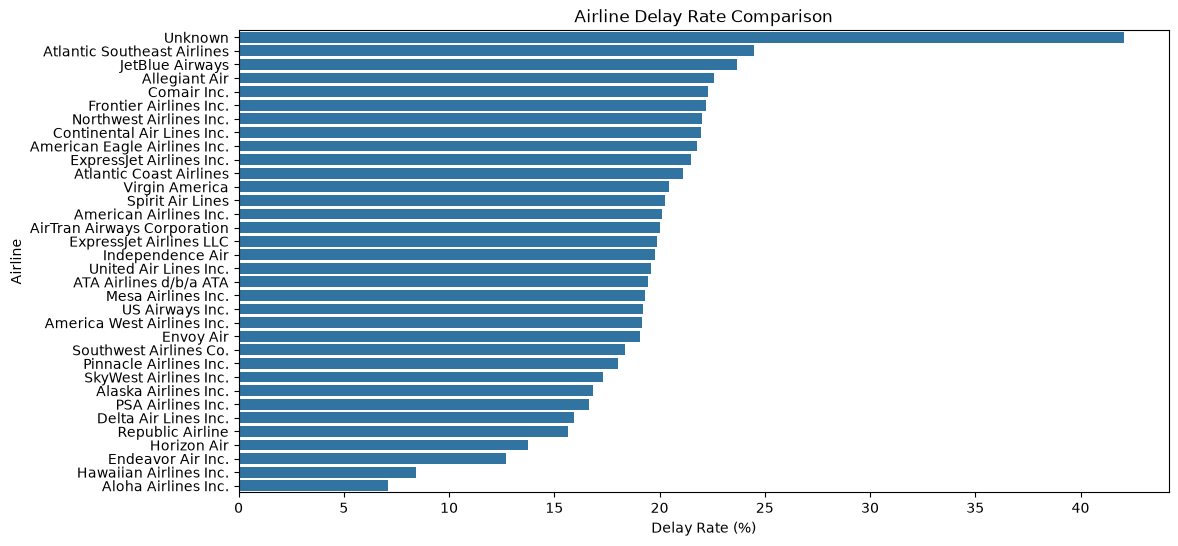

In [13]:
plt.figure(figsize=(12, 6))

sns.barplot(
    data=airline_analysis.sort_values('Delay_Rate_%', ascending=False),
    x='Delay_Rate_%',
    y='carrier_name'
)

plt.title('Airline Delay Rate Comparison')
plt.xlabel('Delay Rate (%)')
plt.ylabel('Airline')
plt.show()

In [14]:
# Remove Unknown airline for airline comparison
airline_clean = airline_analysis[
    airline_analysis['carrier_name'] != 'Unknown'
].copy()

# Sort by delay rate
airline_clean = airline_clean.sort_values(
    'Delay_Rate_%',
    ascending=False
)

display(airline_clean)

,carrier_name,Total_Flights,Delayed_Flights,Cancelled_Flights,Diverted_Flights,Total_Delay_Minutes,Delay_Rate_%,Avg_Delay_Minutes
9,Atlantic Southeast Airlines,2526762.0,618201.0,68385.0,5346.0,36380279.0,24.466135,14.397984
21,JetBlue Airways,4026171.0,953638.0,74475.0,11750.0,62862075.0,23.685979,15.613364
3,Allegiant Air,465457.0,105195.0,21857.0,1345.0,7395779.0,22.600369,15.889285
10,Comair Inc.,1765828.0,394146.0,58036.0,3584.0,21168261.0,22.320747,11.987725
17,Frontier Airlines Inc.,1665570.0,369671.0,20350.0,2316.0,21876820.0,22.194864,13.134735
23,Northwest Airlines Inc.,2766867.0,609742.0,33834.0,5556.0,29540965.0,22.037272,10.676684
11,Continental Air Lines Inc.,2447164.0,537252.0,20395.0,6949.0,30000006.0,21.954066,12.259091
7,American Eagle Airlines Inc.,5184465.0,1129087.0,178259.0,11901.0,64423618.0,21.778274,12.426281
15,ExpressJet Airlines Inc.,7113679.0,1529090.0,191993.0,22301.0,98092859.0,21.495066,13.789329
8,Atlantic Coast Airlines,374247.0,79078.0,11960.0,729.0,4903170.0,21.129895,13.101428


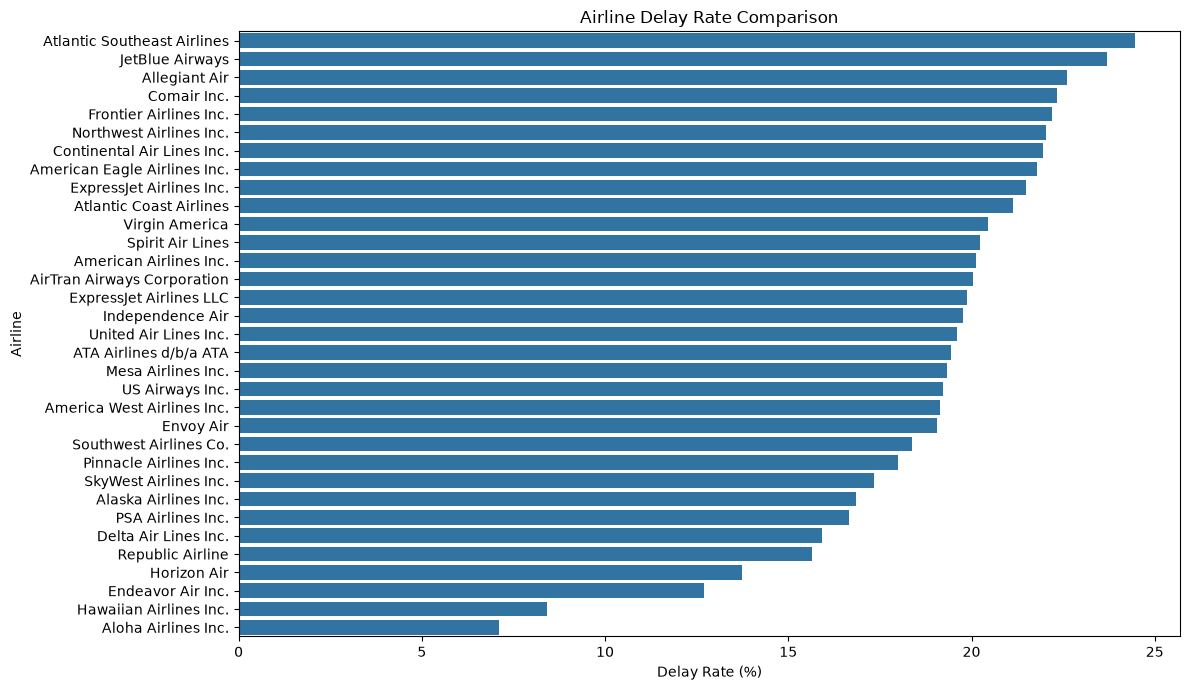

In [15]:
# Airline Delay Rate Chart

plt.figure(figsize=(12, 7))

sns.barplot(
    data=airline_clean,
    x='Delay_Rate_%',
    y='carrier_name'
)

plt.title('Airline Delay Rate Comparison')
plt.xlabel('Delay Rate (%)')
plt.ylabel('Airline')
plt.tight_layout()
plt.show()

In [2]:
import sys
print(sys.executable)

C:\Users\CBM\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe


In [4]:
import sys
print(sys.executable)

C:\Users\CBM\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe


In [3]:
airport_analysis = df.groupby(
    ['airport', 'airport_name']
).agg(
    Total_Flights=('arr_flights', 'sum'),
    Delayed_Flights=('arr_del15', 'sum'),
    Total_Delay_Minutes=('arr_delay', 'sum'),
    Cancelled_Flights=('arr_cancelled', 'sum')
).reset_index()

airport_analysis['Delay_Rate_%'] = (
    airport_analysis['Delayed_Flights']
    / airport_analysis['Total_Flights'].replace(0, np.nan)
) * 100

airport_analysis = airport_analysis[
    airport_analysis['Total_Flights'] >= 100
]

top_10_airports = airport_analysis.sort_values(
    'Delay_Rate_%',
    ascending=False
).head(10)

display(top_10_airports)

,airport,airport_name,Total_Flights,Delayed_Flights,Total_Delay_Minutes,Cancelled_Flights,Delay_Rate_%
372,SOP,"Pinehurst/Southern Pines, NC: Moore County",317.0,133.0,8050.0,6.0,41.955836
145,FOE,"Topeka, KS: Topeka Regional",449.0,164.0,11582.0,29.0,36.525612
67,CDB,"Cold Bay, AK: Cold Bay Airport",262.0,90.0,3212.0,9.0,34.351145
40,BIH,"Bishop, CA: Bishop Airport",261.0,86.0,7498.0,13.0,32.950192
192,ILG,"Wilmington, DE: New Castle",2120.0,687.0,44552.0,49.0,32.405660
367,SLE,"Salem, OR: McNary Field",880.0,281.0,9645.0,1.0,31.931818
243,MCN,"Macon, GA: Middle Georgia Regional",6483.0,2050.0,129325.0,155.0,31.621163
290,OTH,"North Bend/Coos Bay, OR: Southwest Oregon Regi...",8631.0,2516.0,159450.0,246.0,29.150736
131,EWR,"Newark, NJ: Newark Liberty International",2385265.0,670034.0,47297459.0,78509.0,28.090548
200,ISO,"Kinston, NC: Kinston Regional Jetport at Stall...",1456.0,407.0,25764.0,32.0,27.953297


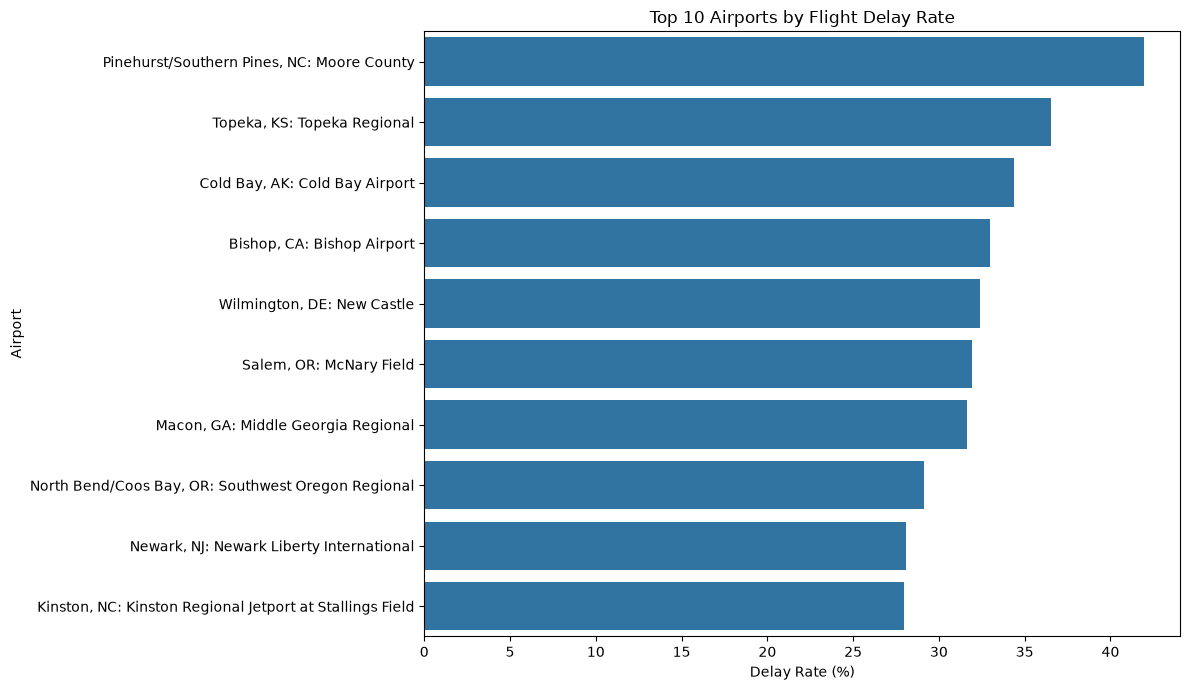

In [4]:
plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_10_airports,
    x='Delay_Rate_%',
    y='airport_name'
)

plt.title('Top 10 Airports by Flight Delay Rate')
plt.xlabel('Delay Rate (%)')
plt.ylabel('Airport')
plt.tight_layout()
plt.show()

In [5]:
# Total delay minutes by reason

delay_reasons = pd.DataFrame({
    'Reason': [
        'Carrier Delay',
        'Weather Delay',
        'NAS Delay',
        'Security Delay',
        'Late Aircraft Delay'
    ],
    'Total_Minutes': [
        df['carrier_delay'].sum(),
        df['weather_delay'].sum(),
        df['nas_delay'].sum(),
        df['security_delay'].sum(),
        df['late_aircraft_delay'].sum()
    ]
})

delay_reasons = delay_reasons.sort_values(
    'Total_Minutes', ascending=False
)

display(delay_reasons)

,Reason,Total_Minutes
4,Late Aircraft Delay,506796286.0
0,Carrier Delay,408520433.0
2,NAS Delay,349128350.0
1,Weather Delay,70036591.0
3,Security Delay,2290908.0


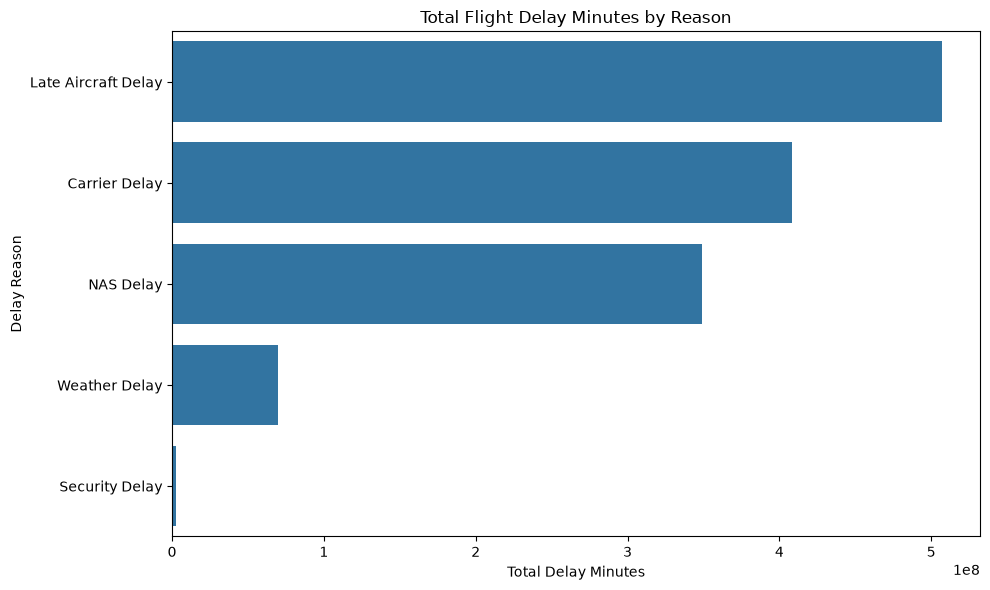

In [6]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=delay_reasons,
    x='Total_Minutes',
    y='Reason'
)

plt.title('Total Flight Delay Minutes by Reason')
plt.xlabel('Total Delay Minutes')
plt.ylabel('Delay Reason')

plt.tight_layout()
plt.show()

In [7]:
monthly_analysis = df.groupby('month').agg(
    Total_Flights=('arr_flights', 'sum'),
    Delayed_Flights=('arr_del15', 'sum'),
    Total_Delay_Minutes=('arr_delay', 'sum'),
    Cancelled_Flights=('arr_cancelled', 'sum')
).reset_index()

monthly_analysis['Delay_Rate_%'] = (
    monthly_analysis['Delayed_Flights']
    / monthly_analysis['Total_Flights'].replace(0, np.nan)
) * 100

monthly_analysis['Average_Delay_Minutes'] = (
    monthly_analysis['Total_Delay_Minutes']
    / monthly_analysis['Total_Flights'].replace(0, np.nan)
)

display(monthly_analysis.round(2))

,month,Total_Flights,Delayed_Flights,Total_Delay_Minutes,Cancelled_Flights,Delay_Rate_%,Average_Delay_Minutes
0,1,9954720.0,1930267.0,110991145.0,282018.0,19.39,11.15
1,2,9155599.0,1804212.0,103189056.0,270032.0,19.71,11.27
2,3,10526778.0,1949141.0,109732780.0,282138.0,18.52,10.42
3,4,9939940.0,1735261.0,99456709.0,262716.0,17.46,10.01
4,5,10058211.0,1862118.0,108505731.0,133944.0,18.51,10.79
5,6,10163259.0,2323140.0,142912106.0,160095.0,22.86,14.06
6,7,10662159.0,2367328.0,147878506.0,168781.0,22.20,13.87
7,8,10708061.0,2151167.0,128606729.0,174036.0,20.09,12.01
8,9,9839722.0,1434348.0,78557928.0,136006.0,14.58,7.98
9,10,10283955.0,1686899.0,89932256.0,115363.0,16.40,8.74


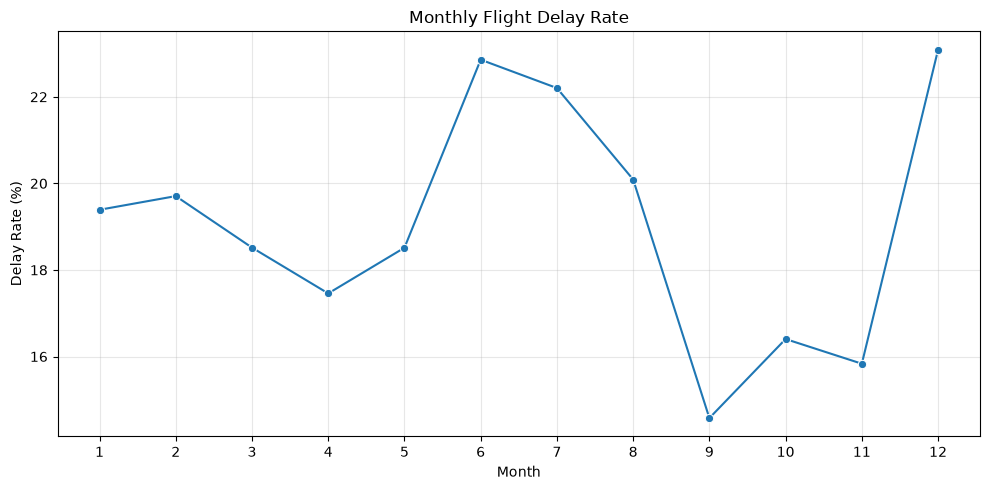

In [8]:
plt.figure(figsize=(10, 5))

sns.lineplot(
    data=monthly_analysis,
    x='month',
    y='Delay_Rate_%',
    marker='o'
)

plt.title('Monthly Flight Delay Rate')
plt.xlabel('Month')
plt.ylabel('Delay Rate (%)')
plt.xticks(range(1, 13))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [9]:
monthly_analysis = df.groupby('month').agg(
    Total_Flights=('arr_flights', 'sum'),
    Delayed_Flights=('arr_del15', 'sum'),
    Total_Delay_Minutes=('arr_delay', 'sum'),
    Cancelled_Flights=('arr_cancelled', 'sum')
).reset_index()

monthly_analysis['Delay_Rate_%'] = (
    monthly_analysis['Delayed_Flights']
    / monthly_analysis['Total_Flights'].replace(0, np.nan)
) * 100

monthly_analysis['Average_Delay_Minutes'] = (
    monthly_analysis['Total_Delay_Minutes']
    / monthly_analysis['Total_Flights'].replace(0, np.nan)
)

display(monthly_analysis.round(2))

,month,Total_Flights,Delayed_Flights,Total_Delay_Minutes,Cancelled_Flights,Delay_Rate_%,Average_Delay_Minutes
0,1,9954720.0,1930267.0,110991145.0,282018.0,19.39,11.15
1,2,9155599.0,1804212.0,103189056.0,270032.0,19.71,11.27
2,3,10526778.0,1949141.0,109732780.0,282138.0,18.52,10.42
3,4,9939940.0,1735261.0,99456709.0,262716.0,17.46,10.01
4,5,10058211.0,1862118.0,108505731.0,133944.0,18.51,10.79
5,6,10163259.0,2323140.0,142912106.0,160095.0,22.86,14.06
6,7,10662159.0,2367328.0,147878506.0,168781.0,22.20,13.87
7,8,10708061.0,2151167.0,128606729.0,174036.0,20.09,12.01
8,9,9839722.0,1434348.0,78557928.0,136006.0,14.58,7.98
9,10,10283955.0,1686899.0,89932256.0,115363.0,16.40,8.74


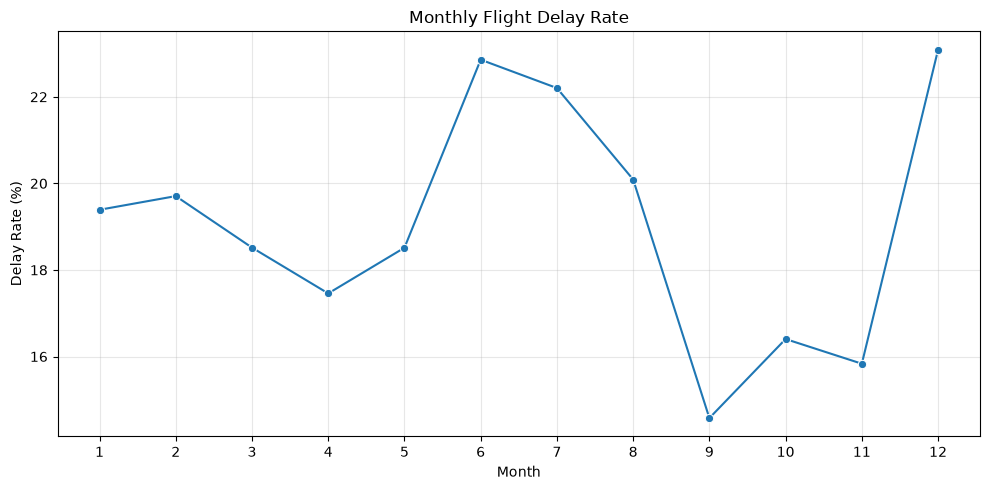

In [10]:
plt.figure(figsize=(10, 5))

sns.lineplot(
    data=monthly_analysis,
    x='month',
    y='Delay_Rate_%',
    marker='o'
)

plt.title('Monthly Flight Delay Rate')
plt.xlabel('Month')
plt.ylabel('Delay Rate (%)')
plt.xticks(range(1, 13))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [11]:
import os

os.makedirs("../sql", exist_ok=True)

df.to_csv(
    "../sql/airline_delay_cleaned.csv",
    index=False
)

print("Cleaned dataset exported successfully!")
print("Rows:", len(df))

Cleaned dataset exported successfully!
Rows: 318017


In [5]:
import sys
!{sys.executable} -m pip install pandas numpy matplotlib seaborn

Defaulting to user installation because normal site-packages is not writeable
  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
   ---------------------------------------- 0.0/9.6 MB ? eta -:--:--
   - -------------------------------------- 0.3/9.6 MB ? eta -:--:--
   -- ------------------------------------- 0.5/9.6 MB 1.2 MB/s eta 0:00:08
   --- ------------------------------------ 0.8/9.6 MB 1.3 MB/s eta 0:00:07
   ---- ----------------------------------- 1.0/9.6 MB 1.4 MB/s eta 0:00:07
   ----- ---------------------------------- 1.3/9.6 MB 1.4 MB/s eta 0:00:06
   ------- -------------------------------- 1.8/9.6 MB 1.5 MB/s eta 0:00:06
   -------- ------------------------------- 2.1/9.6 MB 1.5 MB/s eta 0:00:06
   --------- ------------------------------ 2.4/9.6 MB 1.5 MB/s eta 0:00:05
   ---------- ----------------------------- 2.6/9.6 MB 1.5 MB/s eta 0:00:05
   ----------- ---------------------------- 2.9


[notice] A new release of pip is available: 26.1.2 -> 26.2.1
[notice] To update, run: C:\Users\CBM\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sqlite3

df = pd.read_csv("../dataset/Airline_Delay_Cause.csv")

# Handle missing values
numeric_columns = df.select_dtypes(include="number").columns
df[numeric_columns] = df[numeric_columns].fillna(0)

categorical_columns = df.select_dtypes(include="object").columns
df[categorical_columns] = df[categorical_columns].fillna("Unknown")

print("Dataset loaded successfully!")
print("Shape:", df.shape)

Dataset loaded successfully!
Shape: (318017, 21)


C:\Users\CBM\AppData\Local\Temp\ipykernel_46260\299538204.py:13: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_columns = df.select_dtypes(include="object").columns


In [3]:
db_path = "../sql/airline_delay.db"

conn = sqlite3.connect(db_path)

df.to_sql(
    "airline_delay",
    conn,
    if_exists="replace",
    index=False
)

print("Data imported successfully into SQLite!")

Data imported successfully into SQLite!


In [4]:

query = """
SELECT
    carrier_name,
    SUM(arr_flights) AS total_flights,
    SUM(arr_del15) AS delayed_flights,
    ROUND(
        100.0 * SUM(arr_del15) /
        NULLIF(SUM(arr_flights), 0), 2
    ) AS delay_rate_percent
FROM airline_delay
WHERE carrier_name <> 'Unknown'
GROUP BY carrier_name
ORDER BY delay_rate_percent DESC
LIMIT 10;
"""

result = pd.read_sql_query(query, conn)
display(result)


,carrier_name,total_flights,delayed_flights,delay_rate_percent
0,Atlantic Southeast Airlines,2526762.0,618201.0,24.47
1,JetBlue Airways,4026171.0,953638.0,23.69
2,Allegiant Air,465457.0,105195.0,22.60
3,Comair Inc.,1765828.0,394146.0,22.32
4,Frontier Airlines Inc.,1665570.0,369671.0,22.19
5,Northwest Airlines Inc.,2766867.0,609742.0,22.04
6,Continental Air Lines Inc.,2447164.0,537252.0,21.95
7,American Eagle Airlines Inc.,5184465.0,1129087.0,21.78
8,ExpressJet Airlines Inc.,7113679.0,1529090.0,21.50
9,Atlantic Coast Airlines,374247.0,79078.0,21.13


In [5]:

monthly_query = """
SELECT
    month,
    SUM(arr_flights) AS total_flights,
    SUM(arr_del15) AS delayed_flights,
    ROUND(
        100.0 * SUM(arr_del15) /
        NULLIF(SUM(arr_flights), 0), 2
    ) AS delay_rate_percent,
    ROUND(SUM(arr_delay), 0) AS total_delay_minutes
FROM airline_delay
GROUP BY month
ORDER BY month;
"""

monthly_result = pd.read_sql_query(monthly_query, conn)
display(monthly_result)


,month,total_flights,delayed_flights,delay_rate_percent,total_delay_minutes
0,1,9954720.0,1930267.0,19.39,110991145.0
1,2,9155599.0,1804212.0,19.71,103189056.0
2,3,10526778.0,1949141.0,18.52,109732780.0
3,4,9939940.0,1735261.0,17.46,99456709.0
4,5,10058211.0,1862118.0,18.51,108505731.0
5,6,10163259.0,2323140.0,22.86,142912106.0
6,7,10662159.0,2367328.0,22.20,147878506.0
7,8,10708061.0,2151167.0,20.09,128606729.0
8,9,9839722.0,1434348.0,14.58,78557928.0
9,10,10283955.0,1686899.0,16.40,89932256.0


In [6]:

reasons_query = """
SELECT
    'Late Aircraft' AS delay_reason,
    SUM(late_aircraft_delay) AS total_delay_minutes
FROM airline_delay

UNION ALL

SELECT
    'Carrier',
    SUM(carrier_delay)
FROM airline_delay

UNION ALL

SELECT
    'National Aviation System',
    SUM(nas_delay)
FROM airline_delay

UNION ALL

SELECT
    'Weather',
    SUM(weather_delay)
FROM airline_delay

UNION ALL

SELECT
    'Security',
    SUM(security_delay)
FROM airline_delay

ORDER BY total_delay_minutes DESC;
"""

reasons_result = pd.read_sql_query(reasons_query, conn)
display(reasons_result)


,delay_reason,total_delay_minutes
0,Late Aircraft,506796286.0
1,Carrier,408520433.0
2,National Aviation System,349128350.0
3,Weather,70036591.0
4,Security,2290908.0


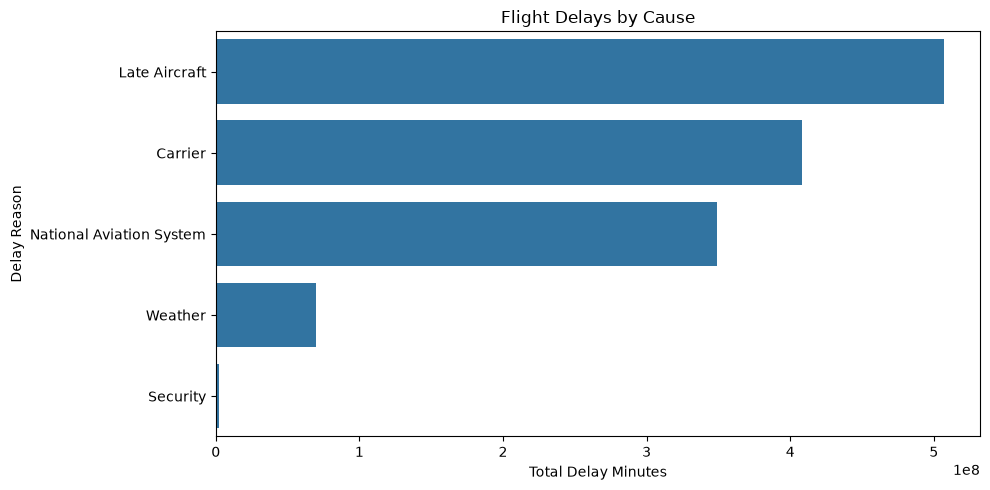

In [7]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=reasons_result,
    x="total_delay_minutes",
    y="delay_reason"
)

plt.title("Flight Delays by Cause")
plt.xlabel("Total Delay Minutes")
plt.ylabel("Delay Reason")
plt.tight_layout()
plt.show()

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv("../dataset/Airline_Delay_Cause.csv")


In [4]:
reason_totals = pd.DataFrame({
    "Delay Reason": [
        "Carrier",
        "Weather",
        "National Aviation System",
        "Security",
        "Late Aircraft"
    ],
    "Delay Minutes": [
        df["carrier_delay"].sum(),
        df["weather_delay"].sum(),
        df["nas_delay"].sum(),
        df["security_delay"].sum(),
        df["late_aircraft_delay"].sum()
    ]
})

display(reason_totals)

,Delay Reason,Delay Minutes
0,Carrier,408520433.0
1,Weather,70036591.0
2,National Aviation System,349128350.0
3,Security,2290908.0
4,Late Aircraft,506796286.0


In [2]:

import pandas as pd

df = pd.read_csv("../dataset/Airline_Delay_Cause.csv")

reason_totals = pd.DataFrame({
    "Delay Reason": [
        "Carrier",
        "Weather",
        "National Aviation System",
        "Security",
        "Late Aircraft"
    ],
    "Delay Minutes": [
        df["carrier_delay"].sum(),
        df["weather_delay"].sum(),
        df["nas_delay"].sum(),
        df["security_delay"].sum(),
        df["late_aircraft_delay"].sum()
    ]
})

display(reason_totals)


,Delay Reason,Delay Minutes
0,Carrier,408520433.0
1,Weather,70036591.0
2,National Aviation System,349128350.0
3,Security,2290908.0
4,Late Aircraft,506796286.0


In [3]:

import pandas as pd

df = pd.read_csv("../dataset/Airline_Delay_Cause.csv")

reason_totals = pd.DataFrame({
    "Delay Reason": [
        "Carrier",
        "Weather",
        "National Aviation System",
        "Security",
        "Late Aircraft"
    ],
    "Delay Minutes": [
        df["carrier_delay"].sum(),
        df["weather_delay"].sum(),
        df["nas_delay"].sum(),
        df["security_delay"].sum(),
        df["late_aircraft_delay"].sum()
    ]
})

reason_totals


,Delay Reason,Delay Minutes
0,Carrier,408520433.0
1,Weather,70036591.0
2,National Aviation System,349128350.0
3,Security,2290908.0
4,Late Aircraft,506796286.0


In [4]:
display(reason_totals)

,Delay Reason,Delay Minutes
0,Carrier,408520433.0
1,Weather,70036591.0
2,National Aviation System,349128350.0
3,Security,2290908.0
4,Late Aircraft,506796286.0
